In [26]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.inspection import DecisionBoundaryDisplay


In [ ]:
df = pd.read_csv("iris.csv")

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
print(df.shape)
print(df["species"].value_counts())

(150, 5)
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [4]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [5]:
print(df.isnull().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


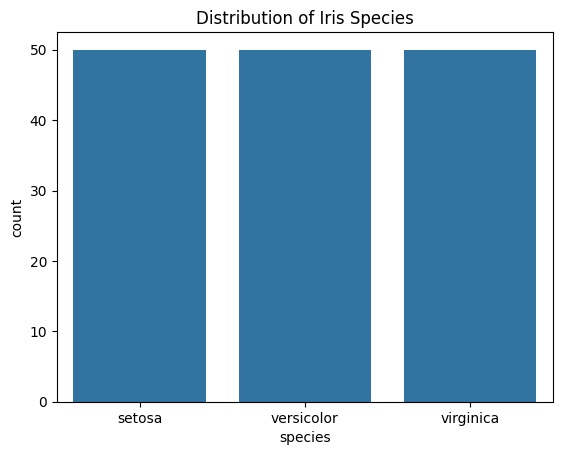

In [9]:
sns.countplot(data=df, x="species")
plt.title("Distribution of Iris Species")
plt.show()

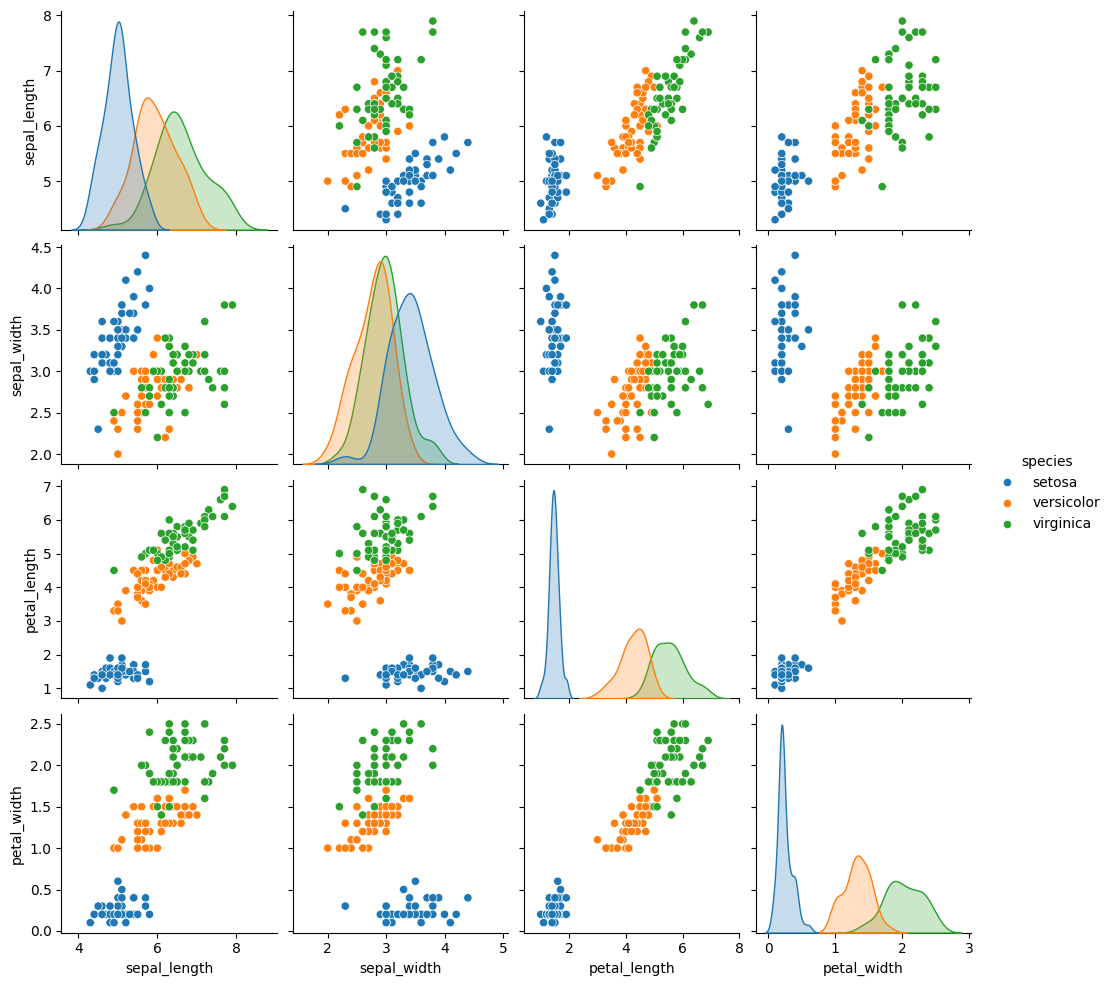

In [10]:
sns.pairplot(df, hue="species")
plt.show()

In [11]:
X = df.drop("species", axis=1)
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (120, 4)
Testing data shape: (30, 4)


In [ ]:
lr_model = LogisticRegression(max_iter=200)
lr_model.fit(X_train_scaled, y_train)
lr_predictions = lr_model.predict(X_test_scaled)
print("Logistic Regression training complete!")
print("First 10 predictions:", lr_predictions[:10])

Logistic Regression training complete!
First 10 predictions: ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_predictions = dt_model.predict(X_test)
print("Decision Tree training complete!")
print("First 10 predictions:", dt_predictions[:10])

Decision Tree training complete!
First 10 predictions: ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [20]:
# Logistic Regression evaluation
print("LOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(y_test, lr_predictions))
print(classification_report(y_test, lr_predictions))

# Decision Tree evaluation
print("DECISION TREE")
print("Accuracy:", accuracy_score(y_test, dt_predictions))
print(classification_report(y_test, dt_predictions))

LOGISTIC REGRESSION
Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

DECISION TREE
Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



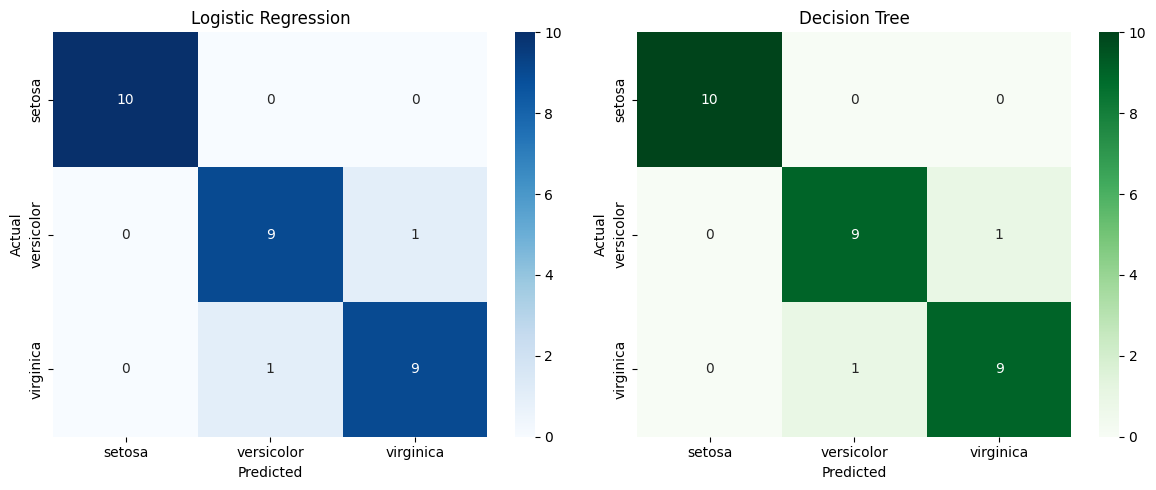

In [22]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
cm_lr = confusion_matrix(y_test, lr_predictions)
sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Blues",
    xticklabels=lr_model.classes_,
    yticklabels=lr_model.classes_,
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Decision Tree
cm_dt = confusion_matrix(y_test, dt_predictions)
sns.heatmap(
    cm_dt, annot=True, fmt="d", cmap="Greens",
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_,
    ax=axes[1]
)
axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [24]:

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, dt_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions, average="weighted"),
        precision_score(y_test, dt_predictions, average="weighted")
    ],
    "Recall": [
        recall_score(y_test, lr_predictions, average="weighted"),
        recall_score(y_test, dt_predictions, average="weighted")
    ],
    "F1-Score": [
        f1_score(y_test, lr_predictions, average="weighted"),
        f1_score(y_test, dt_predictions, average="weighted")
    ]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.933,0.933,0.933,0.933


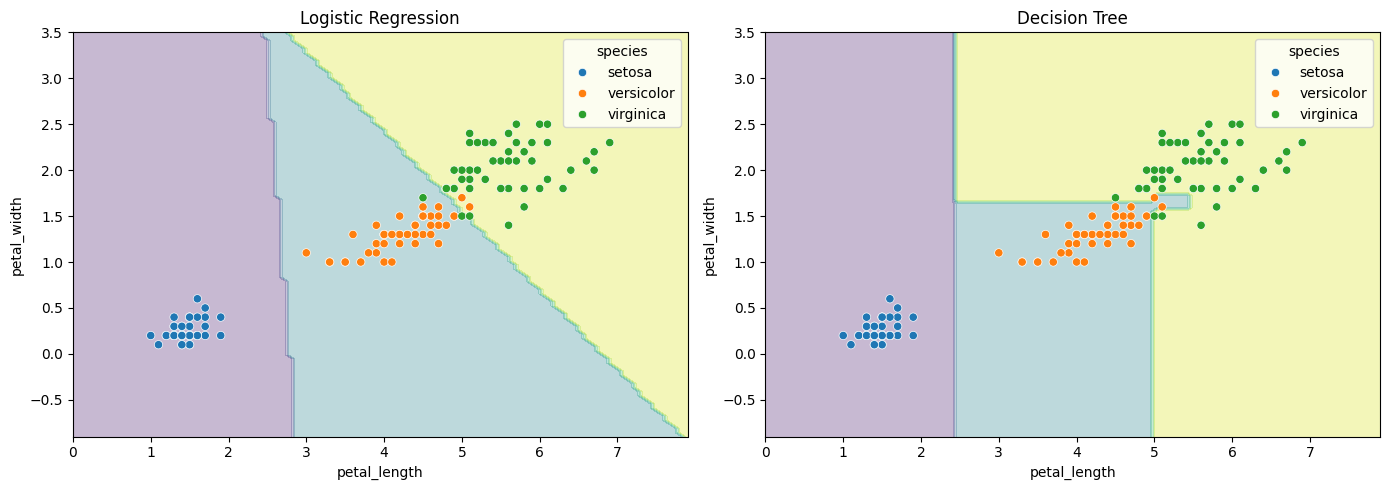

In [27]:
# Select two useful features
X_2d = df[["petal_length", "petal_width"]]
y_labels = df["species"]

# Encode species into numbers
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y_labels)

# Train models using only these two features
lr_2d = LogisticRegression(max_iter=200)
dt_2d = DecisionTreeClassifier(random_state=42)

lr_2d.fit(X_2d, y_labels)
dt_2d.fit(X_2d, y_labels)

# Plot decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in [
    (axes[0], lr_2d, "Logistic Regression"),
    (axes[1], dt_2d, "Decision Tree")
]:
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_2d,
        response_method="predict",
        alpha=0.3,
        ax=ax
    )

    sns.scatterplot(
        data=df,
        x="petal_length",
        y="petal_width",
        hue="species",
        ax=ax
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()

In [28]:
print("IRIS FLOWER CLASSIFICATION PROJECT")
print("-" * 40)

print("Dataset samples:", len(df))
print("Number of features:", X.shape[1])
print("Number of classes:", y.nunique())
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nMODEL COMPARISON")
display(results.round(3))

best_model = results.loc[results["Accuracy"].idxmax(), "Model"]
print("\nBest model based on test accuracy:", best_model)

IRIS FLOWER CLASSIFICATION PROJECT
----------------------------------------
Dataset samples: 150
Number of features: 4
Number of classes: 3
Training samples: 120
Testing samples: 30

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.933,0.933,0.933,0.933



Best model based on test accuracy: Logistic Regression
